<a href="https://colab.research.google.com/github/AlessandraSozzi/BDMS_STI_2026/blob/main/notebooks/BDC_2a_Extract_Satellite_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

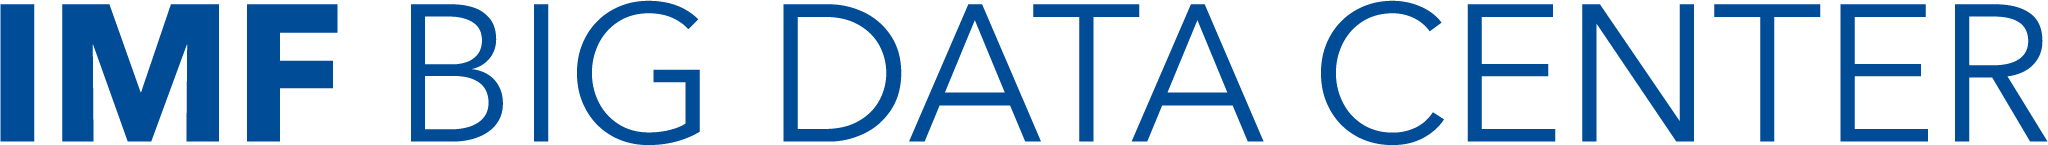

# Satellite data extraction

---

<br>**Contributors:** [Iyke Maduako](imaduako@imf.org), [Alberto Sanchez](asanchez3@imf.org), [Alessandra Sozzi](asozzi@imf.org), [Dharana Rijal](drijal@imf.org)
<br> **Last update:** 2026-10-24 (Created: 2025-May)
<br> **Description:** This notebook extracts and saves data from Satellite Imagery and other sources so that they can be used as inputs for GDP Nowcasting
<br> **References:**

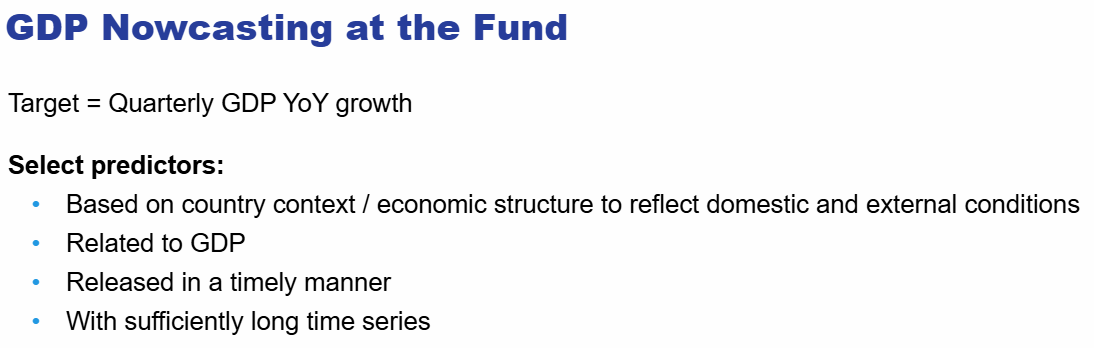

**Satellite Indicators can serve as proxies for economic activity**

NTL (Nighttime Lights): Measures the brightness of artificial light emitted from the Earth's surface at night.

NDVI & EVI: Measure the greenness and density of live vegetation to assess plant health.

NO2: Measures the concentration of nitrogen dioxide gas in the lower atmosphere, typically indicating pollution.

Precipitation: Measures the total amount of daily rainfall and snowfall over a given area.

FAO vegetation indices: Measures agricultural drought severity by calculating vegetation health and the percentage of stressed cropland.

## Set-up

Import libraries

In [ ]:
import ee
import pandas as pd
import numpy as np
import os
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Authenticate Google Earth Engine

⏰**Enter your Google Cloud project name**

In [ ]:
ee.Authenticate()
my_project_name = 'ee-bdc-cd' # USE YOUR OWN GOOGLE CLOUD PROJECT NAME HERE
ee.Initialize(project=my_project_name)

### Define scope

Country of interest

In [ ]:
CountryName = "Mongolia"
CountryCode = "MNG"

# Define country boundary (in this case using USDOS 2017)
country = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017").filter(ee.Filter.eq("country_na", CountryName))

Time range

In [ ]:

startYear = 2010
endYear = 2026

Set Path for outputs

In [ ]:
ROOT = "/content/drive/MyDrive/BDMS_STI_2026-main/" #if using colab
data_folder = "data"
data_path = os.path.join(ROOT, data_folder)
data_path

'/content/drive/MyDrive/BDMS_STI_2026-main/data'

## Extract Satellite Data

⚠ ***NOTE: Data extraction can take a long time. We will skip this part during the workshop. Feel free to try on your own***

### **Extract NO2 data**

In [ ]:
# Select the Sentinel-5P NO2 dataset
dataset = ee.ImageCollection("COPERNICUS/S5P/NRTI/L3_NO2")

# Prepare Data For Download
geometry = country.geometry()

# Create an empty list to store feature collections for each month
tables = []

# Loop through each year and month
for year in range(startYear, endYear + 1):
    for month in range(1, 13):
        # Filter the dataset by the current year and month
        filteredDataset = dataset.filter(ee.Filter.calendarRange(year, year, "year")).filter(ee.Filter.calendarRange(month, month, "month"))

        # Reduce the dataset to calculate sum and mean tropospheric_NO2_column_number_density
        temporalReducer = ee.Reducer.sum()
        stats3 = filteredDataset.select("tropospheric_NO2_column_number_density").reduce(temporalReducer)
        stats = stats3.reduceRegion(reducer=ee.Reducer.sum().combine(ee.Reducer.mean(), "", True),
                                    geometry=geometry,
                                    scale=5000,
                                    maxPixels=1e9)

        # Extract sum_avg and mean_avg
        sum_avg = "NA"
        mean_avg = "NA"
        if stats.getInfo():
            sum_avg = stats.get("tropospheric_NO2_column_number_density_sum_sum")
            mean_avg = stats.get("tropospheric_NO2_column_number_density_sum_mean")
            #print(sum_avg)

        # Create a dictionary with properties for the year, month, sum, and mean
        feature_dict = {
            "year": year,
            "month": month,
            "sum_no2":sum_avg.getInfo() if sum_avg != "NA" else None,
            "mean_no2": mean_avg.getInfo() if mean_avg != "NA" else None
        }

        # Append the dictionary to the list of tables
        tables.append(feature_dict)


In [ ]:
# Convert the list of dictionaries to a Pandas DataFrame
df1 = pd.DataFrame(tables)
df1.tail(13)

In [ ]:
# Save the data:
file_name1 = f"{CountryName}_NO2_{startYear}_{endYear}.csv"
file_path1 = os.path.join(data_path, file_name1)
df1.to_csv(file_path1, index=False)
print(f"Saved data for {CountryName} at {file_path1}")

### **Extract NDVI data**

In [ ]:
# Select the MOD13A3 dataset
dataset = ee.ImageCollection("MODIS/061/MOD13A3").filterBounds(country)

# Prepare Data For Download
geometry = country.geometry()

# Create an empty list to store feature collections for each month
tables = []

# Loop through each year and month
for year in range(startYear, endYear + 1):
    for month in range(1, 13):
        # Filter the dataset by the current year and month
        filteredDataset = dataset.filter(ee.Filter.calendarRange(year, year, "year")).filter(ee.Filter.calendarRange(month, month, "month"))

        # Reduce the dataset to calculate sum and mean NDVI
        temporalReducer = ee.Reducer.sum()
        stats3 = filteredDataset.select("NDVI").reduce(temporalReducer)
        stats = stats3.reduceRegion(reducer=ee.Reducer.sum().combine(ee.Reducer.mean(), "", True),
                                    geometry=geometry,
                                    scale=5000,
                                    maxPixels=1e9)

        # Extract sum_avg and mean_avg
        sum_avg = "NA"
        mean_avg = "NA"
        if stats.getInfo():
            sum_avg = stats.get("NDVI_sum_sum")
            mean_avg = stats.get("NDVI_sum_mean")

        # Create a dictionary with properties for the year, month, sum, and mean
        feature_dict = {
            "year": year,
            "month": month,
            "sum_ndvi": sum_avg.getInfo() if sum_avg != "NA" else None,
            "mean_ndvi": mean_avg.getInfo() if mean_avg != "NA" else None
        }

        # Append the dictionary to the list of tables
        tables.append(feature_dict)



In [ ]:
# Convert the list of dictionaries to a Pandas DataFrame
df2 = pd.DataFrame(tables)
df2.tail(13)

,year,month,sum_ndvi,mean_ndvi
191,2025,12,7.965797e+07,870.349413
192,2026,1,5.598066e+07,611.732102
193,2026,2,6.581897e+07,719.163805
194,2026,3,1.177491e+08,1286.476771
195,2026,4,1.377805e+08,1505.273046
196,2026,5,1.836418e+08,2008.164577
197,2026,6,2.589333e+08,2835.860608
198,2026,7,3.140643e+08,3436.041969
199,2026,8,3.231265e+08,3537.731944
200,2026,9,2.781495e+08,3047.283605


In [ ]:
# Save the data:
file_name2 = f"{CountryName}_NDVI_{startYear}_{endYear}.csv"
file_path2 = os.path.join(data_path, file_name2)
df2.to_csv(file_path2, index=False)
print(f"Saved data for {CountryName} at {file_path2}")

Saved data for Mongolia at /content/drive/MyDrive/BDMS_STI_2026-main/data/Mongolia_NDVI_Stats_2010_2026.csv


### **Extract EVI data**

In [ ]:
# Select the MOD13A3 dataset
dataset = ee.ImageCollection("MODIS/061/MOD13A3").filterBounds(country)

# Prepare Data For Download
geometry = country.geometry()

# Create an empty list to store feature collections for each month
tables = []

# Loop through each year and month
for year in range(startYear, endYear + 1):
    for month in range(1, 13):
        # Filter the dataset by the current year and month
        filteredDataset = dataset.filter(ee.Filter.calendarRange(year, year, "year")).filter(ee.Filter.calendarRange(month, month, "month"))

        # Reduce the dataset to calculate sum and mean EVI
        temporalReducer = ee.Reducer.sum()
        stats3 = filteredDataset.select("EVI").reduce(temporalReducer)
        stats = stats3.reduceRegion(reducer=ee.Reducer.sum().combine(ee.Reducer.mean(), "", True),
                                    geometry=geometry,
                                    scale=5000,
                                    maxPixels=1e9)

        # Extract sum_avg and mean_avg
        sum_avg = "NA"
        mean_avg = "NA"
        if stats.getInfo():
            sum_avg = stats.get("EVI_sum_sum")
            mean_avg = stats.get("EVI_sum_mean")

        # Create a dictionary with properties for the year, month, sum, and mean
        feature_dict = {
            "year": year,
            "month": month,
            "sum_evi": sum_avg.getInfo() if sum_avg != "NA" else None,
            "mean_evi": mean_avg.getInfo() if mean_avg != "NA" else None
        }

        # Append the dictionary to the list of tables
        tables.append(feature_dict)

In [ ]:
# Convert the list of dictionaries to a Pandas DataFrame
df3 = pd.DataFrame(tables)
df3.tail(13)

,year,month,sum_evi,mean_evi
191,2025,12,4.983753e+07,544.528874
192,2026,1,3.580836e+07,391.298088
193,2026,2,4.152245e+07,453.690516
194,2026,3,7.075138e+07,772.999285
195,2026,4,8.114390e+07,886.509375
196,2026,5,1.099516e+08,1202.345633
197,2026,6,1.594791e+08,1746.627625
198,2026,7,1.943069e+08,2125.828257
199,2026,8,1.944638e+08,2129.075263
200,2026,9,1.561244e+08,1710.427540


In [ ]:
# Save the data:
file_name3 = f"{CountryName}_EVI_{startYear}_{endYear}.csv"
file_path3 = os.path.join(data_path, file_name3)
df3.to_csv(file_path3, index=False)
print(f"Saved data for {CountryName} at {file_path3}")

Saved data for Mongolia at /content/drive/MyDrive/BDMS_STI_2026-main/data/Mongolia_EVI_Stats_2010_2026.csv


### **Extract Nighttime Lights data**

In [ ]:
# import socket

# # Set the default socket timeout globally to stop timeout warning
# socket.setdefaulttimeout(60)  # timeout in seconds

# ee.Initialize(project='ee-bdc-cd')

In [ ]:
# Select the VIIRS NTL dataset
dataset = ee.ImageCollection("NASA/VIIRS/002/VNP46A2").filterBounds(country)

# Prepare Data For Download
geometry = country.geometry()

# Create an empty list to store feature collections for each month
tables = []

# Loop through each year and month
for year in range(startYear, endYear + 1):
    for month in range(1, 13):
        # Filter the dataset by the current year and month
        filteredDataset = dataset.filter(ee.Filter.calendarRange(year, year, "year")).filter(ee.Filter.calendarRange(month, month, "month"))

        # Reduce the dataset to calculate sum and mean Gap_Filled_DNB_BRDF_Corrected_NTL
        temporalReducer = ee.Reducer.sum()
        stats3 = filteredDataset.select("Gap_Filled_DNB_BRDF_Corrected_NTL").reduce(temporalReducer)
        stats = stats3.reduceRegion(reducer=ee.Reducer.sum().combine(ee.Reducer.mean(), "", True),
                                    geometry=geometry,
                                    scale=5000,
                                    maxPixels=1e9)

        # Extract sum_avg and mean_avg
        sum_avg = "NA"
        mean_avg = "NA"
        if stats.getInfo():
            sum_avg = stats.get("Gap_Filled_DNB_BRDF_Corrected_NTL_sum_sum")
            mean_avg = stats.get("Gap_Filled_DNB_BRDF_Corrected_NTL_sum_mean")

        # Create a dictionary with properties for the year, month, sum, and mean
        feature_dict = {
            "year": year,
            "month": month,
            "sum_ntl": sum_avg.getInfo() if sum_avg != "NA" else None,
            "mean_ntl": mean_avg.getInfo() if mean_avg != "NA" else None
        }

        # Append the dictionary to the list of tables
        tables.append(feature_dict)


In [ ]:
# Convert the list of dictionaries to a Pandas DataFrame
df4 = pd.DataFrame(tables)
df4.tail(13)

,year,month,sum_ntl,mean_ntl
191,2025,12,6.815296e+05,7.445717
192,2026,1,1.051866e+06,11.491651
193,2026,2,7.727190e+05,8.441962
194,2026,3,5.412630e+05,5.913303
195,2026,4,4.740581e+05,5.179090
196,2026,5,3.867841e+05,4.225620
197,2026,6,2.752033e+05,3.006599
198,2026,7,2.493099e+05,2.723713
199,2026,8,5.566192e+05,6.081070
200,2026,9,6.497078e+05,7.098063


In [ ]:

# Save the data: Uncomment as needed
file_name4 = f"{CountryName}_NTL_{startYear}_{endYear}.csv"
file_path4 = os.path.join(data_path, file_name4)
df4.to_csv(file_path4, index=False)
print(f"Saved data for {CountryName} at {file_path4}")

Saved data for Mongolia at /content/drive/MyDrive/BDMS_STI_2026-main/data/Mongolia_NTL_2010_2026.csv


### **Extract Precipitation data**

In [ ]:
# Select the MOD13A3 dataset
dataset = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").filterBounds(country)

# Prepare Data For Download
geometry = country.geometry()

# Create an empty list to store feature collections for each month
tables = []

# Loop through each year and month
for year in range(startYear, endYear + 1):
    for month in range(1, 13):
        # Filter the dataset by the current year and month
        filteredDataset = dataset.filter(ee.Filter.calendarRange(year, year, "year")).filter(ee.Filter.calendarRange(month, month, "month"))

        # Reduce the dataset to calculate sum and mean precipitation
        temporalReducer = ee.Reducer.sum()
        stats3 = filteredDataset.select("precipitation").reduce(temporalReducer)
        stats = stats3.reduceRegion(reducer=ee.Reducer.sum().combine(ee.Reducer.mean(), "", True), geometry=geometry, scale=5000, maxPixels=1e9)

        # Extract sum_avg and mean_avg
        sum_avg = "NA"
        mean_avg = "NA"
        if stats.getInfo():
            sum_avg = stats.get("precipitation_sum_sum")
            mean_avg = stats.get("precipitation_sum_mean")

        # Create a dictionary with properties for the year, month, sum, and mean
        feature_dict = {
            "year": year,
            "month": month,
            "sum_pcp": sum_avg.getInfo() if sum_avg != "NA" else None,
            "mean_pcp": mean_avg.getInfo() if mean_avg != "NA" else None
        }

        # Append the dictionary to the list of tables
        tables.append(feature_dict)


In [ ]:
# Convert the list of dictionaries to a Pandas DataFrame
df5 = pd.DataFrame(tables)
df5.tail(13)

,year,month,sum_pcp,mean_pcp
191,2025,12,2.114828e+05,2.465159
192,2026,1,1.527291e+05,1.780294
193,2026,2,2.027825e+05,2.363744
194,2026,3,2.313838e+05,2.697136
195,2026,4,4.836760e+05,5.637993
196,2026,5,1.464130e+06,17.066698
197,2026,6,2.618739e+06,30.525456
198,2026,7,3.930854e+06,45.820192
199,2026,8,4.309818e+06,50.237603
200,2026,9,1.144040e+06,13.335558


In [ ]:
# Save the data:
file_name5 = f"{CountryName}_precipitation_{startYear}_{endYear}.csv"
file_path5 = os.path.join(data_path, file_name5)
df5.to_csv(file_path5, index=False)
print(f"Saved data for {CountryName} at {file_path5}")

Saved data for Mongolia at /content/drive/MyDrive/BDMS_STI_2026-main/data/Mongolia_precipitation_Stats_2010_2026.csv


### **Extract Agricultural Indices from FAO**

In [ ]:
import pandas as pd
import os

country_codes = {
    # "Bulgaria": "BGR",
    "Mongolia": "MNG",
}

# Define a function to process country data
def process_country_data(country_name, country_code):
    print(f"Processing data for {country_name} ({country_code})")

    # Base URLs for the datasets
    base_urls = {
        "ASI_Dekad_Season1": f"https://www.fao.org/giews/earthobservation/asis/data/country/{country_code}/MAP_ASI/DATA/ASI_Dekad_Season1_data.csv",
        "NDVI_ADM1": f"https://www.fao.org/giews/earthobservation/asis/data/country/{country_code}/GRAPH_NDVI_AGRI/ndvi_adm1_data.csv",
        "VHI_ADM1_DEKAD": f"https://www.fao.org/giews/earthobservation/asis/data/country/{country_code}/MAP_NDVI_ANOMALY/DATA/vhi_adm1_dekad_data.csv",
    }

    dataframes = {}
    for key, url in base_urls.items():
        file_name = f"{key}_{country_code}.csv"
        print(f"Downloading {file_name} from {url}")
        os.system(f"wget -q -O {file_name} {url}")  # Download the file quietly

        if os.path.exists(file_name):
            with open(file_name, encoding='utf-8', errors='replace') as file:
                df = pd.read_csv(file)  # Read the file after opening it with error handling
            dataframes[key] = df
        else:
            print(f"Failed to download {file_name}. Skipping...")

    # Process and aggregate the data
    result_dfs = {}
    for key, df in dataframes.items():
        if "Date" not in df.columns or "Data" not in df.columns:
            print(f"Invalid format for {key}. Skipping...")
            continue

        if key == "NDVI_ADM1":
            variable_name = "NDVI_Anomaly"
        else:
            variable_name = key.split("_")[0]  # Default behavior

        df['Date'] = pd.to_datetime(df['Date'])
        df['YearMonth'] = df['Date'].dt.to_period('M')
        df_filtered = df[df['Date'].dt.year >= 2010]

        aggregated_df = df_filtered.groupby('YearMonth').agg(
            **{
                f"sum_{variable_name.lower()}": ('Data', 'sum'),
                f"mean_{variable_name.lower()}": ('Data', 'mean'),
            }
        ).reset_index()

        aggregated_df['YearMonth'] = aggregated_df['YearMonth'].dt.to_timestamp()
        result_dfs[key] = aggregated_df

    # Merge all the result DataFrames
    merged_df = None
    for key, df in result_dfs.items():
        if merged_df is None:
            merged_df = df
        else:
            merged_df = pd.merge(merged_df, df, on='YearMonth', how='outer')
    merged_df["year"] = merged_df["YearMonth"].apply(lambda x: str(x)[0:4])
    merged_df["month"] = merged_df["YearMonth"].apply(lambda x: str(x)[5:7])

    return merged_df

# Reads data from selected country only
if CountryName in country_codes:
    country_code = country_codes[CountryName]
    country_df = process_country_data(CountryName, country_code)

    if country_df is not None:
        output_file = f"{CountryName}_merged_VIs_{startYear}_{endYear}.csv"
        file_path_vi = os.path.join(data_path, output_file)
        country_df.to_csv(file_path_vi, index=False)
        print(f"Saved merged data for {CountryName} at {file_path_vi}")
    else:
        print(f"No valid data for {CountryName}. Skipping...")
else:
    print(f"{CountryName} is not in the country list. Please check the name.")


Processing data for Mongolia (MNG)
Saved merged data for Mongolia at /content/drive/MyDrive/BDMS_STI_2026-main/data/Mongolia_merged_VIs_2010_2026.csv


In [ ]:
country_df.tail(13)

## Other alternative datasets. Which other datasets could be useful?

NDWI: Normalized Difference Water Index, which measures the moisture content of vegetation and the presence of open surface water bodies.

NDBI: Normalized Difference Built-up Index (NDBI), also based on surface reflectance.

PM_2.5: Measures the concentration of fine, airborne particulate matter near the Earth's surface. Elevated PM2.5 often signals poor air quality that can cause respiratory and cardiovascular issues for the local population.

AOD (Aerosol Optical Depth): Measures how much atmospheric haze, dust, or smoke prevents sunlight from reaching the ground. A clear sky typically has an AOD below 0.1, whereas high values cause noticeably hazy, brown, or opaque skies.

Temperature: Measures the hourly or daily average air temperature at two meters above the surface.



### **Google Trends**

In addition to the satellite-derived indicators above, we can also download the Search Volume Index (SVI) from Google Trends. In this project we call it the Google Trends Index (GTI). Let's explore: https://trends.google.com/explore

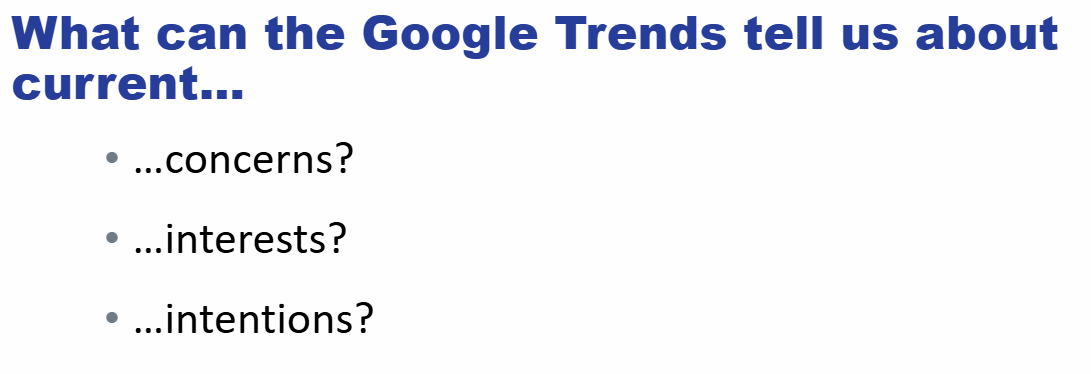

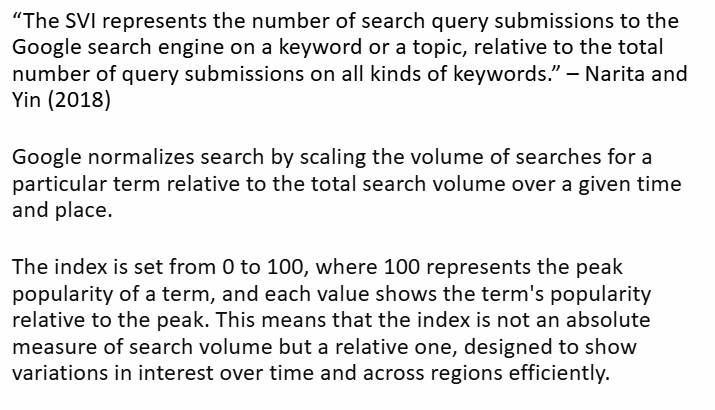

Futoshi Narita, and Rujun Yin. "In Search of Information: Use of Google Trends’ Data to Narrow Information Gaps for Low-income Developing Countries", IMF Working Papers 2018, 286 (2018), accessed 10/28/2026, https://doi.org/10.5089/9781484390177.001

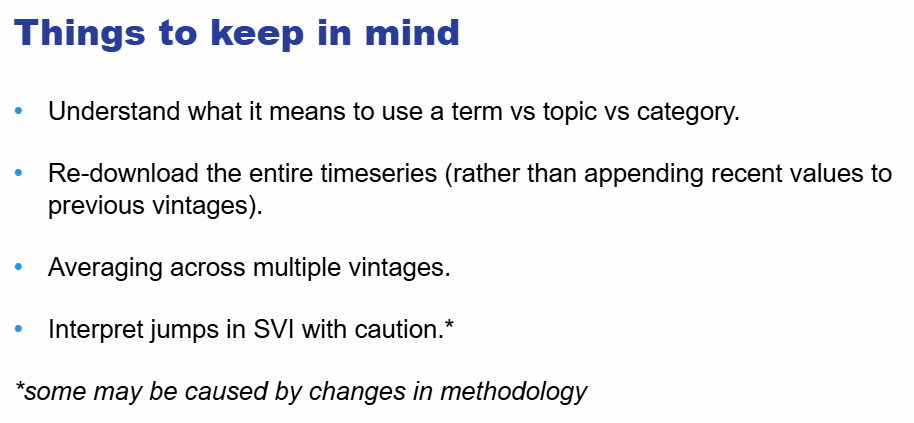

<h3> ⏰ To read in the downloaded dataset(s): Don't forget to adjust the path, if different than above! We have below the GTI for tourism pre-downloaded from Google Trends.</h3>

In [ ]:
data_path

'/content/drive/MyDrive/BDMS_STI_2026-main/data'

In [ ]:
CountryCode

'MNG'

In [ ]:
import pandas as pd

# Construct the file path using string formating
file_name4 = f"{CountryName}_GTI_{startYear}_{endYear}_browser.csv"
file_path4 = os.path.join(data_path, file_name4)
df_Ntl = pd.read_csv(file_path4)
df_Ntl

,date,year,month,gti_tourism
0,1/1/2010,2010,1,7
1,2/1/2010,2010,2,5
2,3/1/2010,2010,3,8
3,4/1/2010,2010,4,8
4,5/1/2010,2010,5,9
...,...,...,...,...
196,5/1/2026,2026,5,49
197,6/1/2026,2026,6,45
198,7/1/2026,2026,7,33
199,8/1/2026,2026,8,22
